### Calibration par zone ERCOT — facteurs d'échelle + industriel data-driven

Coast's calibration (`RES_SCALE=1.6`, `COM_SCALE=1.3`, flat 4,500 MW industrial) was fitted on
Coast alone and **does not transfer**: applied statewide with no industrial at all it already
reaches 105% of the real ERCOT peak. Now that every ERCOT weather zone has a real load reference
(via the bus `Area_Name` field), each zone gets its own calibration.

**Two changes from the Coast method.**

1. **The industrial constant is fitted, not guessed.** Coast used a flat 4,500 MW placeholder
   chosen by hand. Here the model is
   `ERCOT_zone(t) = RES * res(t) + COM * com(t) + IND`
   solved by non-negative least squares — so `IND` is a *data-driven estimate of the
   weather-insensitive baseload* of each zone, not an assumption. It is still a constant, i.e.
   still a placeholder for a real industrial model, but one the data chooses.

2. **Blocked seasonal 4-fold CV**, same protocol as the rest of the pipeline (see
   [[temporal_split_priority]]): fit on three seasons, score on the held-out one. A calibration
   fitted and scored on the same 8,760 hours would be optimistic in exactly the way this project
   has already been burned by once.

**How much shape can an industrial *constant* buy?** Added to an already-fixed prediction, none
at all: `corr(y, a*x + b)` does not depend on `b`. But here `IND` is fitted *jointly* with the two
scales, and that does move the shape a little — without an industrial term the scales are forced
upward to reach the right level, which distorts the residential/commercial mix; with one they are
free to sit at the ratio that actually fits. The effect is real but small (see section 2), so the
constant remains overwhelmingly a magnitude correction, not a cure for the weak-shape zones
(FWEST, WEST).

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.optimize import nnls

exports = Path("../../loadcurves/exports")
statewide_dir = Path("..")
exports_out_dir = statewide_dir / "exports"
metrics_dir = statewide_dir / "metrics"

bus_master = pd.read_csv(statewide_dir / "bus_zone_master.csv", dtype={"COUNTYFP": str})
bus_master["Bus_Number"] = bus_master["Bus_Number"].astype(str)
AREA_TO_ERCOT = {"Coast": "COAST", "East": "EAST", "Far West": "FWEST", "North": "NORTH",
                 "North Central": "NCENT", "South": "SOUTH", "South Central": "SCENT", "West": "WEST"}
bus_master["ercot_zone"] = bus_master["Area_Name"].map(AREA_TO_ERCOT)
bus_ercot = bus_master.set_index("Bus_Number")["ercot_zone"]

def stack(kind):
    parts = []
    for z in ["2A", "2B", "3A", "3B", "4B"]:
        p = exports_out_dir / f"{kind}_bus_load_profiles_8760_{z}.csv"
        if p.exists():
            d = pd.read_csv(p, index_col=0, parse_dates=True)
            d.columns = d.columns.astype(str)
            parts.append(d)
    d = pd.concat(parts, axis=1).fillna(0.0)
    cols = d.columns.intersection(bus_ercot.index)
    return (d[cols].T.groupby(bus_ercot.loc[cols]).sum().T) / 1000.0  # MW

res_z = stack("residential")
com_z = stack("commercial")

ercot = pd.read_excel(exports / "Native_Load_2018.xlsx", sheet_name="Native Load Report")
ercot["HourEnding"] = ercot["HourEnding"].astype(str)
is_dst = ercot["HourEnding"].str.contains(" DST", regex=False)
ercot["HourEnding"] = ercot["HourEnding"].str.replace(" DST", "", regex=False)
mask24 = ercot["HourEnding"].str.contains("24:00")
ercot["HourEnding"] = ercot["HourEnding"].str.replace("24:00", "00:00")
ts = pd.to_datetime(ercot["HourEnding"])
ts.loc[mask24] += pd.Timedelta(days=1)
ercot["date_time"] = ts.dt.tz_localize("US/Central", ambiguous=is_dst, nonexistent="shift_forward")
ercot = ercot.set_index("date_time").tz_convert("Etc/GMT+5")
ercot.index = ercot.index.tz_localize(None)

# ERCOT's duplicated fall-back hour survives the tz conversion; drop duplicate index labels
# on both sides before aligning (2 hours, the known DST discontinuity documented in CLAUDE.md).
ercot = ercot[~ercot.index.duplicated(keep="first")]
res_z = res_z[~res_z.index.duplicated(keep="first")]
com_z = com_z[~com_z.index.duplicated(keep="first")]
common = res_z.index.intersection(ercot.index)
res_z, com_z, ercot = res_z.loc[common], com_z.loc[common], ercot.loc[common]
assert len(res_z) == len(com_z) == len(ercot) == len(common)
ercot["ERCOT_SUM"] = ercot[list(AREA_TO_ERCOT.values())].sum(axis=1)
res_z["ERCOT_SUM"] = res_z.sum(axis=1)
com_z["ERCOT_SUM"] = com_z.sum(axis=1)
print(f"{len(common)} hours aligned, zones: {list(res_z.columns)}")


8758 hours aligned, zones: ['COAST', 'EAST', 'FWEST', 'NCENT', 'NORTH', 'SCENT', 'SOUTH', 'WEST', 'ERCOT_SUM']


#### 1. Fit — full year and blocked seasonal CV

Two model forms per zone: the Coast-style 2-parameter fit (`IND` forced to 0) and the
3-parameter fit that lets the data choose the industrial constant.

In [2]:
SEASON_MONTHS = {"winter": [12, 1, 2], "spring": [3, 4, 5],
                 "summer": [6, 7, 8], "fall": [9, 10, 11]}
ZONES = list(AREA_TO_ERCOT.values()) + ["ERCOT_SUM"]
MISMATCH = {"EAST", "NORTH"}  # case area boundaries != ERCOT's (see ercot_zone_validation)


def fit(r, c, y, with_ind):
    """Non-negative least squares for y ~ RES*r + COM*c (+ IND)."""
    cols = [r.values, c.values] + ([np.ones(len(y))] if with_ind else [])
    coef, _ = nnls(np.column_stack(cols), y.values)
    res_s, com_s = coef[0], coef[1]
    ind = coef[2] if with_ind else 0.0
    return res_s, com_s, ind


def score(r, c, y, p):
    pred = p[0] * r + p[1] * c + p[2]
    err = y - pred
    return {"mae_MW": err.abs().mean(), "rmse_MW": np.sqrt((err ** 2).mean()),
            "pearson": y.corr(pred), "peak_coverage": pred.max() / y.max()}


rows = []
month = res_z.index.month
for z in ZONES:
    r, c, y = res_z[z], com_z[z], ercot[z]
    for with_ind in (False, True):
        p_full = fit(r, c, y, with_ind)
        # blocked seasonal CV: fit on 3 seasons, score on the held-out one
        cv = []
        for season, months in SEASON_MONTHS.items():
            te = np.isin(month, months)
            p = fit(r[~te], c[~te], y[~te], with_ind)
            cv.append(score(r[te], c[te], y[te], p))
        rows.append({
            "zone": z, "model": "RES+COM+IND" if with_ind else "RES+COM",
            "boundary": "MISMATCH" if z in MISMATCH else "ok",
            "RES_SCALE": p_full[0], "COM_SCALE": p_full[1], "IND_MW": p_full[2],
            "cv_mae_MW": np.mean([s["mae_MW"] for s in cv]),
            "cv_rmse_MW": np.mean([s["rmse_MW"] for s in cv]),
            **{f"full_{k}": v for k, v in score(r, c, y, p_full).items()},
        })

cal = pd.DataFrame(rows)
cal.to_csv(metrics_dir / "zone_calibration.csv", index=False)

pd.set_option("display.width", 200)
print("=== Coast-style, no industrial term (IND = 0) ===")
print(cal[cal.model == "RES+COM"].set_index("zone")[
    ["boundary", "RES_SCALE", "COM_SCALE", "cv_mae_MW", "full_pearson", "full_peak_coverage"]].round(3))
print("\n=== With a fitted industrial constant ===")
print(cal[cal.model == "RES+COM+IND"].set_index("zone")[
    ["boundary", "RES_SCALE", "COM_SCALE", "IND_MW", "cv_mae_MW", "full_pearson", "full_peak_coverage"]].round(3))


=== Coast-style, no industrial term (IND = 0) ===
           boundary  RES_SCALE  COM_SCALE  cv_mae_MW  full_pearson  full_peak_coverage
zone                                                                                  
COAST            ok      1.779      2.070   1932.772         0.899               1.184
EAST       MISMATCH      0.888      1.725    222.836         0.909               1.263
FWEST            ok      0.283      9.114    601.540         0.631               1.372
NORTH      MISMATCH      0.891      2.034    124.731         0.902               1.122
NCENT            ok      1.829      2.110   1884.487         0.899               1.198
SOUTH            ok      1.753      1.634    577.838         0.909               1.119
SCENT            ok      1.744      0.657   1001.948         0.899               1.033
WEST             ok      1.353     10.459    226.586         0.807               1.153
ERCOT_SUM        ok      1.722      1.917   6084.907         0.921              

#### 2. What the industrial term buys, per zone

In [3]:
a = cal[cal.model == "RES+COM"].set_index("zone")
b = cal[cal.model == "RES+COM+IND"].set_index("zone")
gain = pd.DataFrame({
    "boundary": a["boundary"],
    "IND_MW": b["IND_MW"],
    "IND_share_of_peak": b["IND_MW"] / ercot[ZONES].max(),
    "cv_mae_no_ind": a["cv_mae_MW"], "cv_mae_with_ind": b["cv_mae_MW"],
    "mae_reduction": 1 - b["cv_mae_MW"] / a["cv_mae_MW"],
    "pearson_no_ind": a["full_pearson"], "pearson_with_ind": b["full_pearson"],
})
print(gain.round(3))
print("\nShape moves only slightly: a constant added to a fixed prediction cannot change a correlation,")
print("but fitting IND jointly with the scales re-balances the residential/commercial mix, which can.")
print(f"\nSum of fitted industrial constants over the 6 well-matched zones: "
      f"{gain.loc[[z for z in AREA_TO_ERCOT.values() if z not in MISMATCH], 'IND_MW'].sum():,.0f} MW")
print(f"Statewide fit (ERCOT_SUM) industrial constant: {gain.loc['ERCOT_SUM', 'IND_MW']:,.0f} MW "
      f"(Coast alone used a hand-picked 4,500 MW)")


           boundary     IND_MW  IND_share_of_peak  cv_mae_no_ind  cv_mae_with_ind  mae_reduction  pearson_no_ind  pearson_with_ind
zone                                                                                                                              
COAST            ok   5593.519              0.276       1932.772         1105.113          0.428           0.899             0.900
EAST       MISMATCH    641.827              0.245        222.836          121.906          0.453           0.909             0.911
FWEST            ok   2236.487              0.612        601.540          212.944          0.646           0.631             0.655
NORTH      MISMATCH    393.230              0.258        124.731           69.225          0.445           0.902             0.905
NCENT            ok   4862.658              0.184       1884.487         1496.401          0.206           0.899             0.901
SOUTH            ok   1541.220              0.250        577.838          303.721  

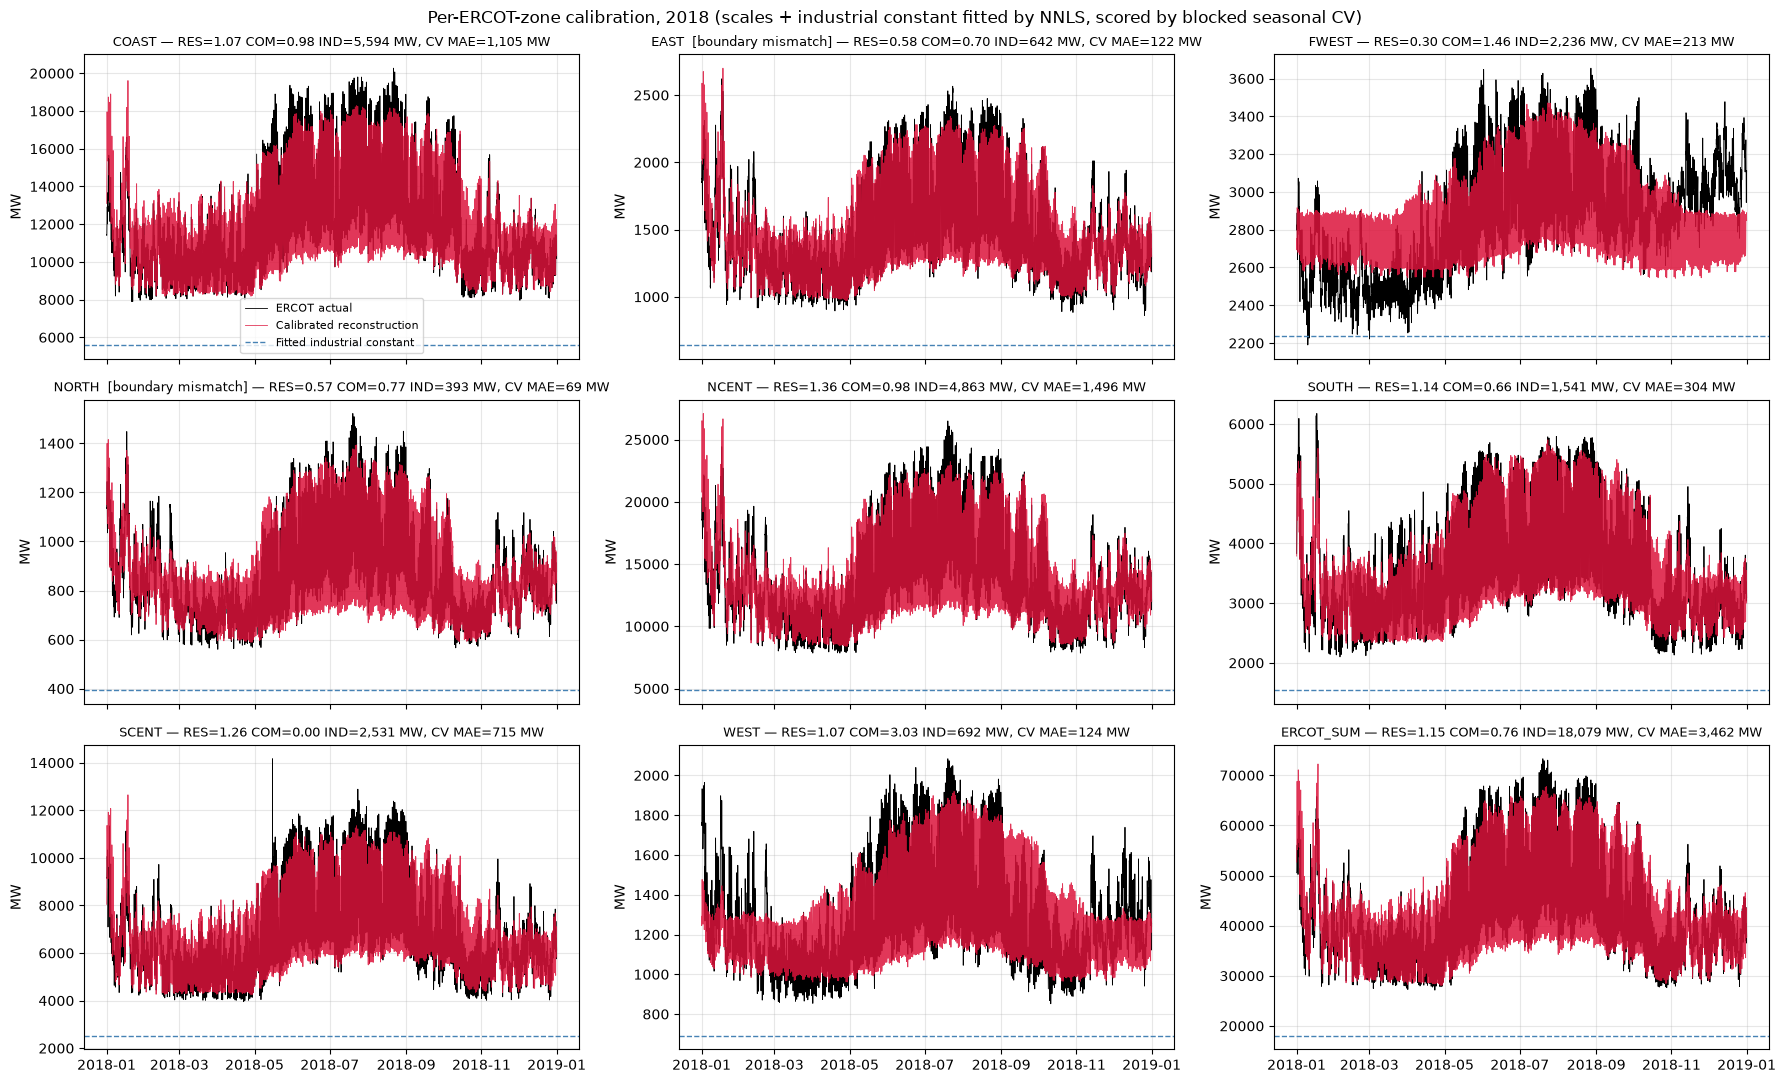

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(18, 11), sharex=True)
for ax, z in zip(axes.ravel(), ZONES):
    p = b.loc[z, ["RES_SCALE", "COM_SCALE", "IND_MW"]].values
    pred = p[0] * res_z[z] + p[1] * com_z[z] + p[2]
    ax.plot(ercot.index, ercot[z], color="black", linewidth=0.6, label="ERCOT actual")
    ax.plot(pred.index, pred, color="crimson", linewidth=0.6, alpha=0.85, label="Calibrated reconstruction")
    ax.axhline(p[2], color="steelblue", linestyle="--", linewidth=1, label="Fitted industrial constant")
    flag = "" if z not in MISMATCH else "  [boundary mismatch]"
    ax.set_title(f"{z}{flag} — RES={p[0]:.2f} COM={p[1]:.2f} IND={p[2]:,.0f} MW, CV MAE={b.loc[z,'cv_mae_MW']:,.0f} MW", fontsize=9)
    ax.set_ylabel("MW"); ax.grid(True, alpha=0.3)
axes.ravel()[0].legend(fontsize=8)
fig.suptitle("Per-ERCOT-zone calibration, 2018 (scales + industrial constant fitted by NNLS, scored by blocked seasonal CV)")
plt.tight_layout(); plt.show()


#### Résumé

Each ERCOT weather zone now has its own `RES_SCALE`, `COM_SCALE` and fitted industrial constant,
scored out-of-sample by blocked seasonal CV, in `metrics/zone_calibration.csv`.

Read the `MISMATCH` rows (EAST, NORTH) as shape-only: the synthetic case's area boundaries do not
coincide with ERCOT's there, so their magnitude coefficients describe a different territory than
the ERCOT column they are fitted against.

The fitted constant is a **data-driven baseload estimate, still not an industrial model**. It
buys a large magnitude improvement and only a marginal shape improvement (the latter coming from
the re-balanced scales, not from the constant itself), so the weak-shape zones (FWEST, WEST) stay
weak — that remains a job for a real, time-varying industrial representation.